In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

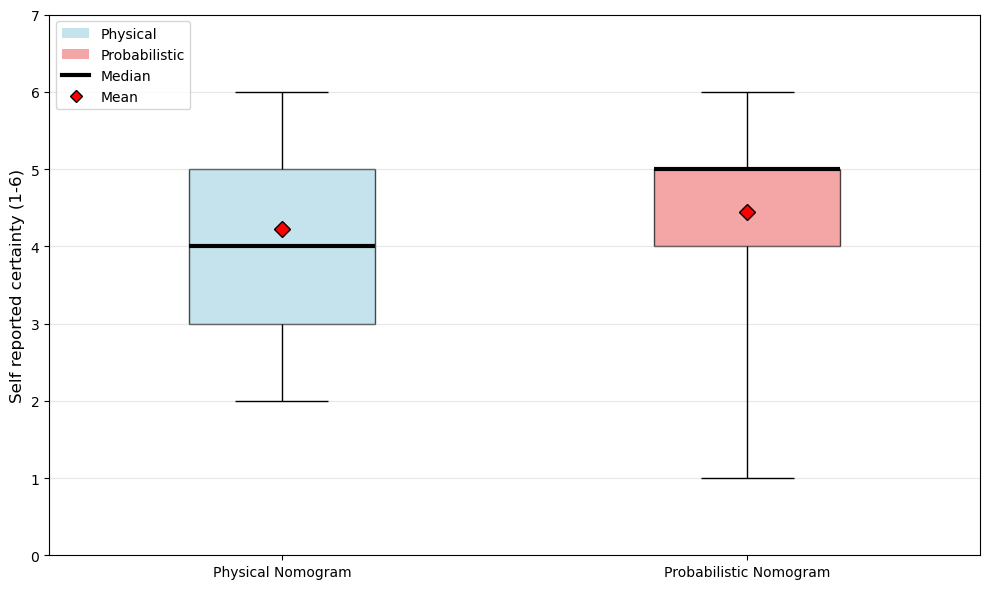

Statistics Summary:
Statistic  Physical     Probabilistic
----------------------------------------
Min        2            1           
Q1         3            4           
Median     4            5           
Q3         5            5           
Max        6            6           
Mean       4.22         4.44        


In [ ]:
# Pre calculated statistics
physical_stats = {
    'Min': 2,
    'Q1': 3,
    'Median': 4,
    'Q3': 5,
    'Max': 6,
    'Mean': 4.22
}

probabilistic_stats = {
    'Min': 1,
    'Q1': 4,
    'Median': 5,
    'Q3': 5,
    'Max': 6,
    'Mean': 4.44
}

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Positions for the box plots
positions = [1, 2]
labels = ['Physical Nomogram', 'Probabilistic Nomogram']

# Manually create box plot elements
def draw_boxplot(ax, pos, stats, color, label):
    """Draw a box plot manually using the statistics"""
    
    # Box (Q1 to Q3)
    box_height = stats['Q3'] - stats['Q1']
    box = plt.Rectangle((pos-0.2, stats['Q1']), 0.4, box_height, 
                       facecolor=color, alpha=0.7, edgecolor='black')
    ax.add_patch(box)
    
    # Median line
    ax.hlines(stats['Median'], pos-0.2, pos+0.2, colors='black', linewidth=3)
    
    # Whiskers
    ax.vlines(pos, stats['Min'], stats['Q1'], colors='black', linewidth=1)
    ax.hlines(stats['Min'], pos-0.1, pos+0.1, colors='black', linewidth=1)
    ax.vlines(pos, stats['Q3'], stats['Max'], colors='black', linewidth=1)
    ax.hlines(stats['Max'], pos-0.1, pos+0.1, colors='black', linewidth=1)
    
    # Mean (red diamond)
    ax.plot(pos, stats['Mean'], marker='D', color='red', markersize=8, 
            markeredgecolor='black', markeredgewidth=1)
    
    return box

# Draw both box plots
physical_box = draw_boxplot(ax, 1, physical_stats, 'lightblue', 'Physical')
probabilistic_box = draw_boxplot(ax, 2, probabilistic_stats, 'lightcoral', 'Probabilistic')

# Customize the plot
ax.set_xlim(0.5, 2.5)
ax.set_ylim(0, 7)
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel('Self reported certainty (1-6)', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

# Add legend
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, facecolor='lightblue', alpha=0.7, label='Physical'),
    plt.Rectangle((0, 0), 1, 1, facecolor='lightcoral', alpha=0.7, label='Probabilistic'),
    plt.Line2D([0], [0], color='black', linewidth=3, label='Median'),
    plt.Line2D([0], [0], marker='D', color='red', linestyle='None', 
               markeredgecolor='black', markersize=6, label='Mean')
]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()

# Print the statistics
print("Statistics Summary:")
print(f"{'Statistic':<10} {'Physical':<12} {'Probabilistic':<12}")
print("-" * 40)
print(f"{'Min':<10} {physical_stats['Min']:<12} {probabilistic_stats['Min']:<12}")
print(f"{'Q1':<10} {physical_stats['Q1']:<12} {probabilistic_stats['Q1']:<12}")
print(f"{'Median':<10} {physical_stats['Median']:<12} {probabilistic_stats['Median']:<12}")
print(f"{'Q3':<10} {physical_stats['Q3']:<12} {probabilistic_stats['Q3']:<12}")
print(f"{'Max':<10} {physical_stats['Max']:<12} {probabilistic_stats['Max']:<12}")
print(f"{'Mean':<10} {physical_stats['Mean']:<12} {probabilistic_stats['Mean']:<12}")


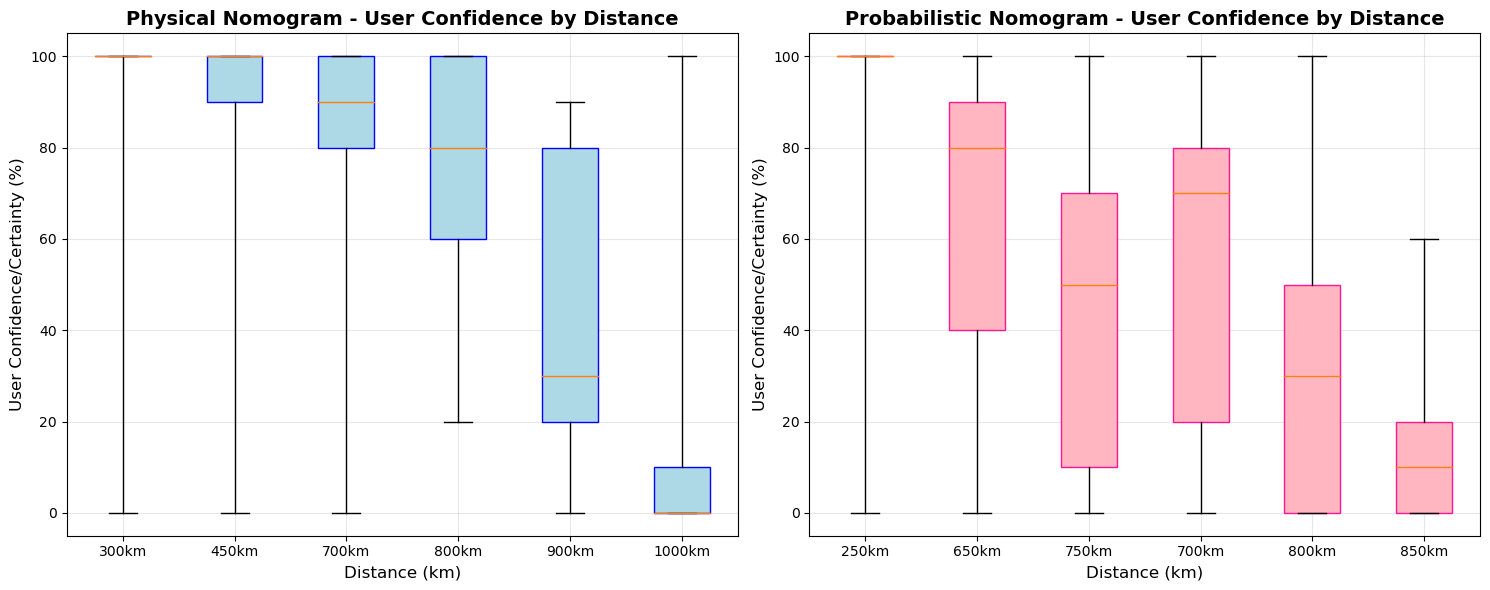

PHYSICAL NOMOGRAM SUMMARY:
300km: Min=0, Max=100, Median=100.0, Mean=86.7
450km: Min=0, Max=100, Median=100.0, Mean=83.3
700km: Min=0, Max=100, Median=90.0, Mean=75.6
800km: Min=20, Max=100, Median=80.0, Mean=75.6
900km: Min=0, Max=90, Median=30.0, Mean=45.6
1000km: Min=0, Max=100, Median=0.0, Mean=21.1

PROBABILISTIC NOMOGRAM SUMMARY:
250km: Min=0, Max=100, Median=100.0, Mean=86.7
650km: Min=0, Max=100, Median=80.0, Mean=61.1
750km: Min=0, Max=100, Median=50.0, Mean=45.6
700km: Min=0, Max=100, Median=70.0, Mean=54.4
800km: Min=0, Max=100, Median=30.0, Mean=34.4
850km: Min=0, Max=60, Median=10.0, Mean=17.8


In [101]:

# Data from Image 1 (Physical Nomogram - Blue) - multiplied by 10 for percentage scale
physical_data = {
    '300km': [100, 100, 100, 100, 100, 100, 0, 100, 80],
    '450km': [100, 100, 90, 100, 100, 100, 0, 100, 60],
    '700km': [100, 90, 90, 100, 80, 100, 0, 100, 20],
    '800km': [90, 50, 80, 100, 60, 100, 80, 100, 20],
    '900km': [10, 0, 20, 90, 30, 80, 60, 90, 30],
    '1000km': [0, 0, 0, 80, 10, 0, 100, 0, 0]
}

# Data from Image 2 (Probabilistic Nomogram - Pink) - multiplied by 10 for percentage scale
probabilistic_data = {
    '250km': [100, 100, 100, 100, 100, 100, 0, 100, 80],
    '650km': [90, 40, 10, 80, 90, 100, 0, 100, 40],
    '750km': [100, 0, 0, 10, 10, 70, 70, 100, 50], 
    '700km': [100, 20, 0, 70, 80, 70, 0, 100, 50],
    '800km': [100, 0, 0, 50, 0, 20, 30, 80, 30],
    '850km': [50, 0, 0, 60, 0, 10, 0, 20, 20],
}

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Physical Nomogram Box Plot (Blue)
physical_positions = []
physical_values = []
physical_labels = []

for i, (km, values) in enumerate(physical_data.items()):
    physical_positions.extend([i+1] * len(values))
    physical_values.extend(values)
    physical_labels.append(km)

# Create box plot for physical data
bp1 = ax1.boxplot([physical_data[km] for km in physical_labels], 
                  positions=range(1, len(physical_labels)+1),
                  patch_artist=True,
                  showfliers=False,  # Don't show outliers as separate points
                  whis=[0, 100])     # Show full range (min to max)

# Color the boxes blue
for patch in bp1['boxes']:
    patch.set_facecolor('lightblue')
    patch.set_edgecolor('blue')

ax1.set_title('Physical Nomogram - User Confidence by Distance', fontsize=14, fontweight='bold')
ax1.set_xlabel('Distance (km)', fontsize=12)
ax1.set_ylabel('User Confidence/Certainty (%)', fontsize=12)
ax1.set_xticklabels(physical_labels)
ax1.set_ylim(-5, 105)
ax1.grid(True, alpha=0.3)

# Probabilistic Nomogram Box Plot (Pink)
probabilistic_positions = []
probabilistic_values = []
probabilistic_labels = []

for i, (km, values) in enumerate(probabilistic_data.items()):
    probabilistic_positions.extend([i+1] * len(values))
    probabilistic_values.extend(values)
    probabilistic_labels.append(km)

# Create box plot for probabilistic data
bp2 = ax2.boxplot([probabilistic_data[km] for km in probabilistic_labels], 
                  positions=range(1, len(probabilistic_labels)+1),
                  patch_artist=True,
                  showfliers=False,  # Don't show outliers as separate points
                  whis=[0, 100])     # Show full range (min to max)

# Color the boxes pink
for patch in bp2['boxes']:
    patch.set_facecolor('lightpink')
    patch.set_edgecolor('deeppink')

ax2.set_title('Probabilistic Nomogram - User Confidence by Distance', fontsize=14, fontweight='bold')
ax2.set_xlabel('Distance (km)', fontsize=12)
ax2.set_ylabel('User Confidence/Certainty (%)', fontsize=12)
ax2.set_xticklabels(probabilistic_labels)
ax2.set_ylim(-5, 105)
ax2.grid(True, alpha=0.3)

# Adjust layout and display
plt.tight_layout()
plt.show()

# Print summary statistics
print("PHYSICAL NOMOGRAM SUMMARY:")
print("=" * 40)
for km, values in physical_data.items():
    print(f"{km}: Min={min(values)}, Max={max(values)}, Median={np.median(values):.1f}, Mean={np.mean(values):.1f}")

print("\nPROBABILISTIC NOMOGRAM SUMMARY:")
print("=" * 40)
for km, values in probabilistic_data.items():
    print(f"{km}: Min={min(values)}, Max={max(values)}, Median={np.median(values):.1f}, Mean={np.mean(values):.1f}")

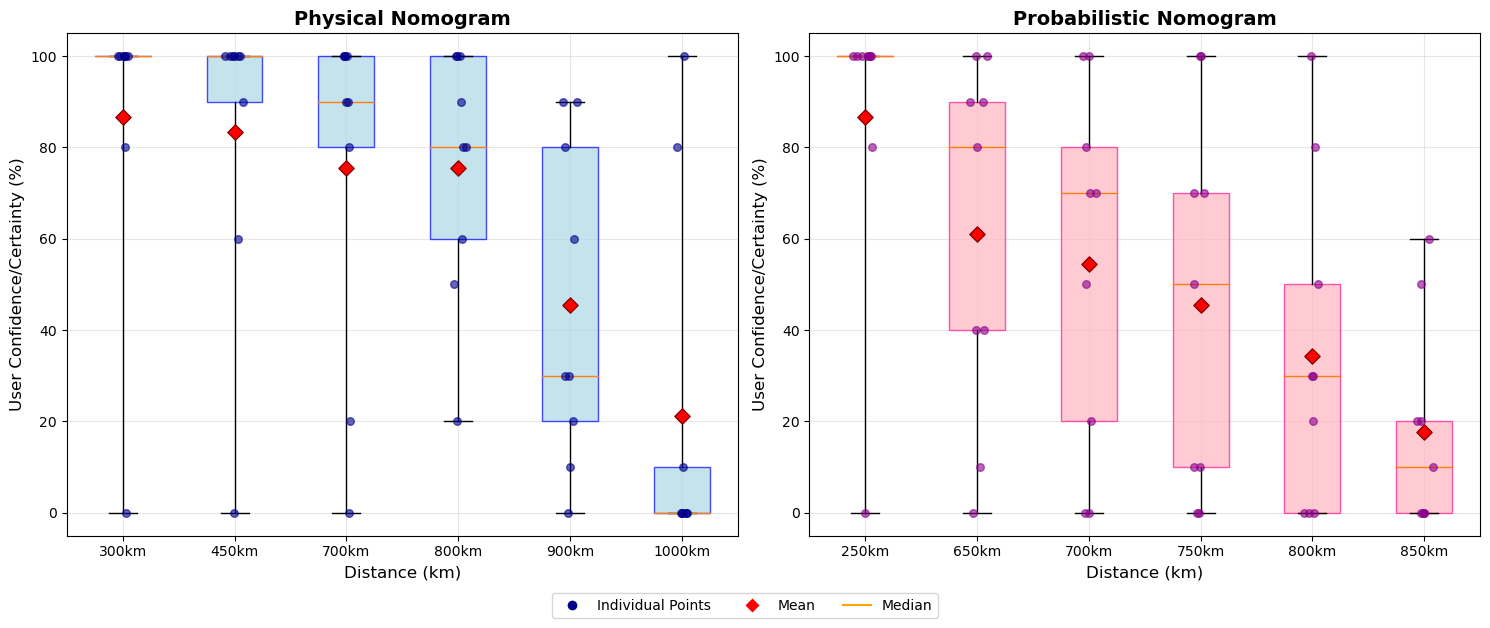

PHYSICAL NOMOGRAM SUMMARY:
300km: Min=0, Max=100, Median=100.0, Mean=86.7
450km: Min=0, Max=100, Median=100.0, Mean=83.3
700km: Min=0, Max=100, Median=90.0, Mean=75.6
800km: Min=20, Max=100, Median=80.0, Mean=75.6
900km: Min=0, Max=90, Median=30.0, Mean=45.6
1000km: Min=0, Max=100, Median=0.0, Mean=21.1

PROBABILISTIC NOMOGRAM SUMMARY:
250km: Min=0, Max=100, Median=100.0, Mean=86.7
650km: Min=0, Max=100, Median=80.0, Mean=61.1
700km: Min=0, Max=100, Median=70.0, Mean=54.4
750km: Min=0, Max=100, Median=50.0, Mean=45.6
800km: Min=0, Max=100, Median=30.0, Mean=34.4
850km: Min=0, Max=60, Median=10.0, Mean=17.8


In [102]:
# Data from Image 1 (Physical Nomogram - Blue) - multiplied by 10 for percentage scale
physical_data = {
    '300km': [100, 100, 100, 100, 100, 100, 0, 100, 80],
    '450km': [100, 100, 90, 100, 100, 100, 0, 100, 60],
    '700km': [100, 90, 90, 100, 80, 100, 0, 100, 20],
    '800km': [90, 50, 80, 100, 60, 100, 80, 100, 20],
    '900km': [10, 0, 20, 90, 30, 80, 60, 90, 30],
    '1000km': [0, 0, 0, 80, 10, 0, 100, 0, 0]
}

# Data from Image 2 (Probabilistic Nomogram - Pink) - multiplied by 10 for percentage scale
probabilistic_data = {
    '250km': [100, 100, 100, 100, 100, 100, 0, 100, 80],
    '650km': [90, 40, 10, 80, 90, 100, 0, 100, 40],
    '700km': [100, 20, 0, 70, 80, 70, 0, 100, 50],
    '750km': [100, 0, 0, 10, 10, 70, 70, 100, 50], 
    '800km': [100, 0, 0, 50, 0, 20, 30, 80, 30],
    '850km': [50, 0, 0, 60, 0, 10, 0, 20, 20],
}

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Physical Nomogram Box Plot (Blue)
physical_labels = list(physical_data.keys())

bp1 = ax1.boxplot([physical_data[km] for km in physical_labels], 
                  positions=range(1, len(physical_labels)+1),
                  patch_artist=True,
                  showfliers=False,  
                  whis=[0, 100])     

# Color the boxes blue
for patch in bp1['boxes']:
    patch.set_facecolor('lightblue')
    patch.set_alpha(0.7)  
    patch.set_edgecolor('blue')


# Add individual points and means for physical data
for i, km in enumerate(physical_labels):
    x_pos = i + 1
    y_values = physical_data[km]
    
    x_jittered = np.random.normal(x_pos, 0.04, size=len(y_values))
    
    ax1.scatter(x_jittered, y_values, alpha=0.6, color='darkblue', s=30, zorder=3)
    
    mean_val = np.mean(y_values)
    ax1.scatter(x_pos, mean_val, color='red', marker='D', s=60, zorder=4, 
                edgecolors='darkred', linewidth=1)

ax1.set_title('Physical Nomogram', fontsize=14, fontweight='bold')
ax1.set_xlabel('Distance (km)', fontsize=12)
ax1.set_ylabel('User Confidence/Certainty (%)', fontsize=12)
ax1.set_xticklabels(physical_labels)
ax1.set_ylim(-5, 105)
ax1.grid(True, alpha=0.3)

# Probabilistic Nomogram Box Plot (Pink)
probabilistic_labels = list(probabilistic_data.keys())

bp2 = ax2.boxplot([probabilistic_data[km] for km in probabilistic_labels], 
                  positions=range(1, len(probabilistic_labels)+1),
                  patch_artist=True,
                  showfliers=False,  
                  whis=[0, 100])     

# Color the boxes pink
for patch in bp2['boxes']:
    patch.set_facecolor('lightpink')
    patch.set_alpha(0.7)  
    patch.set_edgecolor('deeppink')

# Add individual points and means for probabilistic data
for i, km in enumerate(probabilistic_labels):
    x_pos = i + 1
    y_values = probabilistic_data[km]
    
    x_jittered = np.random.normal(x_pos, 0.04, size=len(y_values))
    
    ax2.scatter(x_jittered, y_values, alpha=0.6, color='darkmagenta', s=30, zorder=3)
    
    mean_val = np.mean(y_values)
    ax2.scatter(x_pos, mean_val, color='red', marker='D', s=60, zorder=4, 
                edgecolors='darkred', linewidth=1)

ax2.set_title('Probabilistic Nomogram', fontsize=14, fontweight='bold')
ax2.set_xlabel('Distance (km)', fontsize=12)
ax2.set_ylabel('User Confidence/Certainty (%)', fontsize=12)
ax2.set_xticklabels(probabilistic_labels)
ax2.set_ylim(-5, 105)
ax2.grid(True, alpha=0.3)

# Add legend with Median
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='darkblue', markersize=8, label='Individual Points'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='red', markersize=8, label='Mean'),
    Line2D([0], [0], color='orange', linewidth=1.5, label='Median')

]
fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3)

# Adjust layout and display
plt.tight_layout()
plt.show()

# Print summary statistics
print("PHYSICAL NOMOGRAM SUMMARY:")
print("=" * 40)
for km, values in physical_data.items():
    print(f"{km}: Min={min(values)}, Max={max(values)}, Median={np.median(values):.1f}, Mean={np.mean(values):.1f}")

print("\nPROBABILISTIC NOMOGRAM SUMMARY:")
print("=" * 40)
for km, values in probabilistic_data.items():
    print(f"{km}: Min={min(values)}, Max={max(values)}, Median={np.median(values):.1f}, Mean={np.mean(values):.1f}")


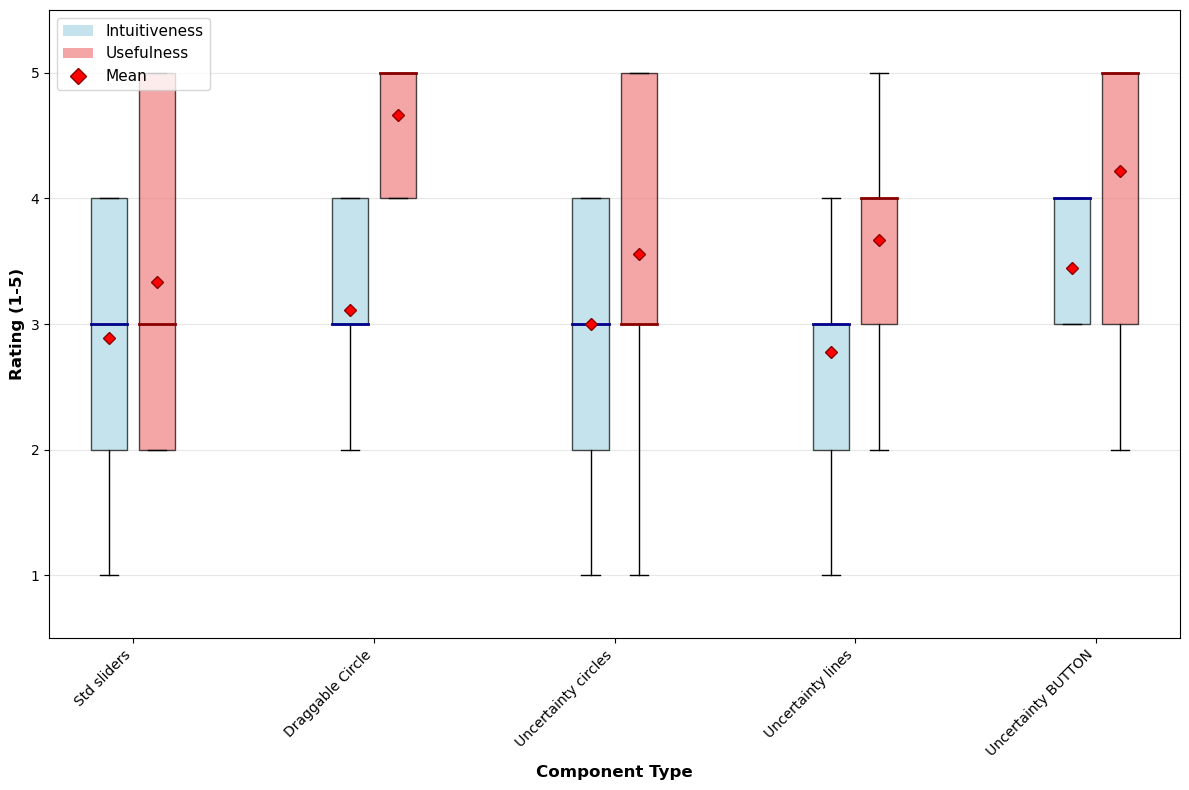

Summary Statistics:

Std sliders:
  Intuitiveness - Median: 3.0, Mean: 2.9, Range: 1-4
  Usefulness    - Median: 3.0, Mean: 3.3, Range: 2-5

Draggable Circle:
  Intuitiveness - Median: 3.0, Mean: 3.1, Range: 1-4
  Usefulness    - Median: 5.0, Mean: 4.7, Range: 4-5

Uncertainty circles:
  Intuitiveness - Median: 3.0, Mean: 3.0, Range: 1-4
  Usefulness    - Median: 3.0, Mean: 3.6, Range: 1-5

Uncertainty lines:
  Intuitiveness - Median: 3.0, Mean: 2.8, Range: 1-4
  Usefulness    - Median: 4.0, Mean: 3.7, Range: 2-5

Uncertainty BUTTON:
  Intuitiveness - Median: 4.0, Mean: 3.4, Range: 1-4
  Usefulness    - Median: 5.0, Mean: 4.2, Range: 2-5


In [96]:
# Extract data from the table - each row alternates between Intuitive and Useful ratings
# Reading the data by columns (components) and separating intuitive/useful pairs
raw_data = [
    [3, 3, 1, 2, 4, 3, 2, 4, 4],  # Std sliders - Intuitive
    [3, 2, 2, 2, 5, 3, 3, 5, 5],  # Std sliders - Useful
    [2, 1, 4, 3, 4, 3, 3, 4, 4],  # Draggable Circle - Intuitive
    [5, 4, 5, 5, 5, 4, 4, 5, 5],  # Draggable Circle - Useful
    [4, 2, 2, 4, 4, 1, 3, 3, 4],  # Uncertainty circles - Intuitive
    [5, 3, 3, 3, 5, 1, 3, 4, 5],  # Uncertainty circles - Useful
    [3, 2, 3, 3, 4, 1, 2, 3, 4],  # Uncertainty lines - Intuitive
    [4, 3, 4, 3, 5, 2, 3, 4, 5],  # Uncertainty lines - Useful
    [1, 4, 4, 4, 4, 4, 3, 3, 4],  # Uncertainty BUTTON - Intuitive
    [2, 5, 5, 5, 5, 5, 3, 3, 5]   # Uncertainty BUTTON - Useful
]

# Organize data by component
components = ['Std sliders', 'Draggable Circle', 'Uncertainty circles', 'Uncertainty lines', 'Uncertainty BUTTON']
intuitive_data = [raw_data[i] for i in range(0, 10, 2)]
useful_data = [raw_data[i] for i in range(1, 10, 2)]

# Create the plot
fig, ax = plt.subplots(figsize=(12, 8))

# Set positions for the box plots with more spacing
x_positions = np.arange(1, len(components) * 2, 2)  # 1, 3, 5, 7, 9
positions_intuitive = x_positions - 0.2
positions_useful = x_positions + 0.2

# Create box plots
bp1 = ax.boxplot(intuitive_data, positions=positions_intuitive, widths=0.3, 
                 patch_artist=True, showfliers=False, showmeans=True,
                 boxprops=dict(facecolor='lightblue', alpha=0.7),
                 medianprops=dict(color='darkblue', linewidth=2),
                 meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='darkred', markersize=6))

bp2 = ax.boxplot(useful_data, positions=positions_useful, widths=0.3, 
                 patch_artist=True, showfliers=False, showmeans=True,
                 boxprops=dict(facecolor='lightcoral', alpha=0.7),
                 medianprops=dict(color='darkred', linewidth=2),
                 meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='darkred', markersize=6))

# Customize the plot
ax.set_xlabel('Component Type', fontsize=12, fontweight='bold')
ax.set_ylabel('Rating (1-5)', fontsize=12, fontweight='bold')
            
# Set x-axis labels and ticks
ax.set_xticks(x_positions)
ax.set_xticklabels(components, rotation=45, ha='right')

# Set y-axis limits and ticks
ax.set_ylim(0.5, 5.5)
ax.set_yticks(range(1, 6))

# Add grid
ax.grid(True, alpha=0.3, axis='y')

# Add legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = [Patch(facecolor='lightblue', alpha=0.7, label='Intuitiveness'),
                   Patch(facecolor='lightcoral', alpha=0.7, label='Usefulness'),
                   Line2D([0], [0], marker='D', color='w', markerfacecolor='red', 
                          markeredgecolor='darkred', markersize=8, label='Mean')]
ax.legend(handles=legend_elements, loc='upper left', fontsize=11)

# Adjust layout to prevent label cutoff
plt.tight_layout()

# # Add median value annotations only
# for i, component in enumerate(components):
#     intuitive_median = np.median(intuitive_data[i])
#     useful_median = np.median(useful_data[i])
    
#     # # Add median values as text annotations
#     # ax.text(x_positions[i] - 0.2, intuitive_median + 0.1, f'{int(intuitive_median)}', 
#     #         ha='center', va='bottom', fontsize=9, fontweight='bold', color='darkblue')
#     # ax.text(x_positions[i] + 0.2, useful_median + 0.1, f'{int(useful_median)}', 
#     #         ha='center', va='bottom', fontsize=9, fontweight='bold', color='darkred')

plt.show()

# Print summary statistics
print("Summary Statistics:")
print("=" * 50)
for i, component in enumerate(components):
    print(f"\n{component}:")
    print(f"  Intuitiveness - Median: {np.median(intuitive_data[i]):.1f}, "
          f"Mean: {np.mean(intuitive_data[i]):.1f}, "
          f"Range: {np.min(intuitive_data[i])}-{np.max(intuitive_data[i])}")
    print(f"  Usefulness    - Median: {np.median(useful_data[i]):.1f}, "
          f"Mean: {np.mean(useful_data[i]):.1f}, "
          f"Range: {np.min(useful_data[i])}-{np.max(useful_data[i])}")

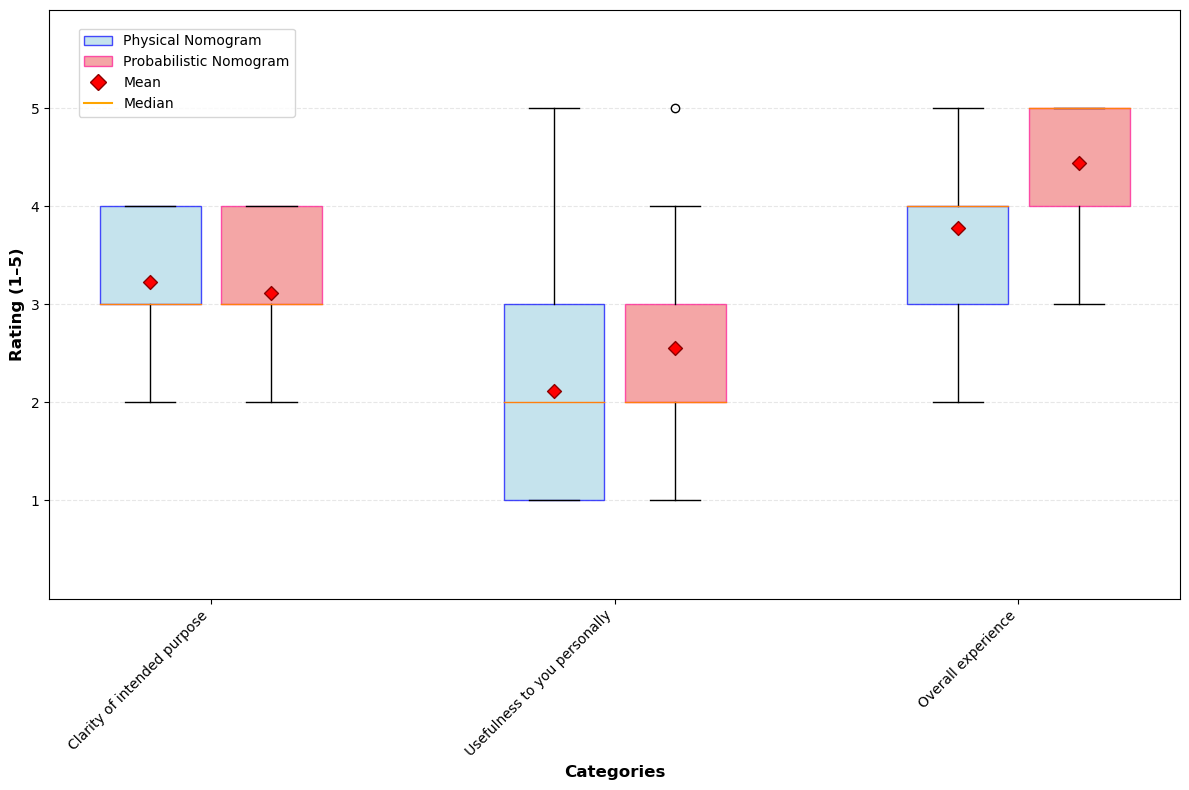

Summary Statistics:

Physical Nomogram (Blue boxes):
Clarity of intended purpose: Mean = 3.22, Median = 3.0, Std = 0.79
Usefulness to you personally: Mean = 2.11, Median = 2.0, Std = 1.29
Overall experience: Mean = 3.78, Median = 4.0, Std = 0.92

Probabilistic Nomogram (Pink boxes):
Clarity of intended purpose: Mean = 3.11, Median = 3.0, Std = 0.74
Usefulness to you personally: Mean = 2.56, Median = 2.0, Std = 1.26
Overall experience: Mean = 4.44, Median = 5.0, Std = 0.68


In [98]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

probabilistic_data = {
    'Clarity of intended purpose': [2, 3, 3, 4, 4, 2, 3, 3, 4],
    'Usefulness to you personally': [2, 3, 2, 2, 3, 1, 1, 4, 5],
    'Initial learning curve': [5, 3, 4, 3, 2, 5, 3, 3, 1],
    'Overall task difficulty': [4, 5, 4, 4, 6, 3, 3, 2, 2],
    'Overall experience': [3, 5, 4, 5, 5, 4, 5, 5, 4]
}

physical_data = {
    'Clarity of intended purpose': [2, 3, 2, 4, 4, 3, 4, 3, 4],
    'Usefulness to you personally': [1, 3, 2, 1, 3, 1, 1, 2, 5],
    'Initial learning curve': [4, 1, 5, 1, 5, 4, 2, 4, 4],
    'Overall task difficulty': [4, 5, 2, 3, 5, 4, 2, 3, 1],
    'Overall experience': [4, 4, 2, 3, 5, 4, 5, 4, 3]
}

# Create the box plot
fig, ax = plt.subplots(figsize=(12, 8))

# Categories to plot
categories = ['Clarity of intended purpose', 'Usefulness to you personally', 'Overall experience']

# Positions
positions_phys = np.arange(len(categories)) * 2 - 0.3
positions_prob = np.arange(len(categories)) * 2 + 0.3

# Boxplots
bp1 = ax.boxplot([physical_data[cat] for cat in categories], 
                 positions=positions_phys, widths=0.5, patch_artist=True)

bp2 = ax.boxplot([probabilistic_data[cat] for cat in categories], 
                 positions=positions_prob, widths=0.5, patch_artist=True)

# Colors (swapped: Physical = blue, Probabilistic = pink)
for patch in bp1['boxes']:
    patch.set_facecolor('lightblue')
    patch.set_edgecolor('blue')
    patch.set_alpha(0.7)

for patch in bp2['boxes']:
    patch.set_facecolor('lightcoral')
    patch.set_edgecolor('deeppink')
    patch.set_alpha(0.7)

# Means as red diamonds
for i, cat in enumerate(categories):
    phys_mean = np.mean(physical_data[cat])
    prob_mean = np.mean(probabilistic_data[cat])
    ax.scatter(positions_phys[i], phys_mean, marker='D', color='red', s=50, zorder=10, 
               edgecolors='darkred', linewidth=1)
    ax.scatter(positions_prob[i], prob_mean, marker='D', color='red', s=50, zorder=10, 
               edgecolors='darkred', linewidth=1)

# Labels
ax.set_xlabel('Categories', fontsize=12, fontweight='bold')
ax.set_ylabel('Rating (1–5)', fontsize=12, fontweight='bold')

ax.set_xticks(np.arange(len(categories)) * 2)
ax.set_xticklabels(categories, rotation=45, ha='right')
ax.set_ylim(0, 6)
ax.set_yticks(range(1, 6))
ax.grid(True, axis='y', alpha=0.3, linestyle='--')

# Legend
legend_elements = [
    Patch(facecolor='lightblue', edgecolor='blue', alpha=0.7, label='Physical Nomogram'),
    Patch(facecolor='lightcoral', edgecolor='deeppink', alpha=0.7, label='Probabilistic Nomogram'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='red',
           markeredgecolor='darkred', markersize=8, label='Mean'),
    Line2D([0], [0], color='orange', linewidth=1.5, label='Median')
]
ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.02, 0.98))

plt.tight_layout()
plt.show()

# Summary statistics
print("Summary Statistics:")
print("\nPhysical Nomogram (Blue boxes):")
for cat in categories:
    data = physical_data[cat]
    print(f"{cat}: Mean = {np.mean(data):.2f}, Median = {np.median(data):.1f}, Std = {np.std(data):.2f}")

print("\nProbabilistic Nomogram (Pink boxes):")
for cat in categories:
    data = probabilistic_data[cat]
    print(f"{cat}: Mean = {np.mean(data):.2f}, Median = {np.median(data):.1f}, Std = {np.std(data):.2f}")


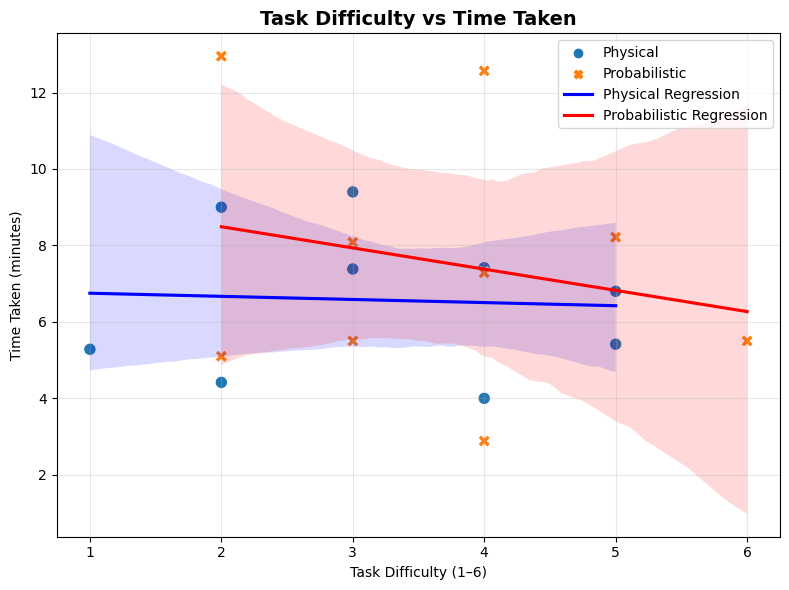

In [81]:

# -----------------------
# Physical Nomogram Data
# -----------------------
time_taken_phys = [
    7*60 + 25,  # 445s
    5*60 + 25,  # 325s
    9*60 + 0,   # 540s
    9*60 + 24,  # 564s
    6*60 + 48,  # 408s
    4*60 + 0,   # 240s
    4*60 + 25,  # 265s
    7*60 + 23,  # 443s
    5*60 + 17   # 317s
]

task_difficulty_phys = [4, 5, 2, 3, 5, 4, 2, 3, 1]

# ----------------------------
# Probabilistic Nomogram Data
# ----------------------------
time_taken_proba = [
    2*60 + 53,   # 173s
    8*60 + 13,   # 493s
    7*60 + 17,   # 437s
    12*60 + 34,  # 754s
    5*60 + 30,   # 330s
    5*60 + 30,   # 330s
    8*60 + 5,    # 485s
    5*60 + 6,    # 306s
    12*60 + 57   # 777s
]

task_difficulty_proba = [4, 5, 4, 4, 6, 3, 3, 2, 2]

# ----------------------------
# Create DataFrame for Seaborn
# ----------------------------
df_phys = pd.DataFrame({
    "Nomogram": "Physical",
    "Difficulty": task_difficulty_phys,
    "Time_minutes": np.array(time_taken_phys) / 60
})

df_proba = pd.DataFrame({
    "Nomogram": "Probabilistic",
    "Difficulty": task_difficulty_proba,
    "Time_minutes": np.array(time_taken_proba) / 60
})

df = pd.concat([df_phys, df_proba])

# ----------------------------
# Plot Scatter + Regression
# ----------------------------
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="Difficulty", y="Time_minutes", hue="Nomogram", style="Nomogram", s=80)
sns.regplot(data=df[df["Nomogram"]=="Physical"], x="Difficulty", y="Time_minutes", scatter=False, color="blue", label="Physical Regression")
sns.regplot(data=df[df["Nomogram"]=="Probabilistic"], x="Difficulty", y="Time_minutes", scatter=False, color="red", label="Probabilistic Regression")

plt.title("Task Difficulty vs Time Taken", fontsize=14, fontweight="bold")
plt.xlabel("Task Difficulty (1–6)")
plt.ylabel("Time Taken (minutes)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Correlation (r) = 0.068, p-value = 0.8619


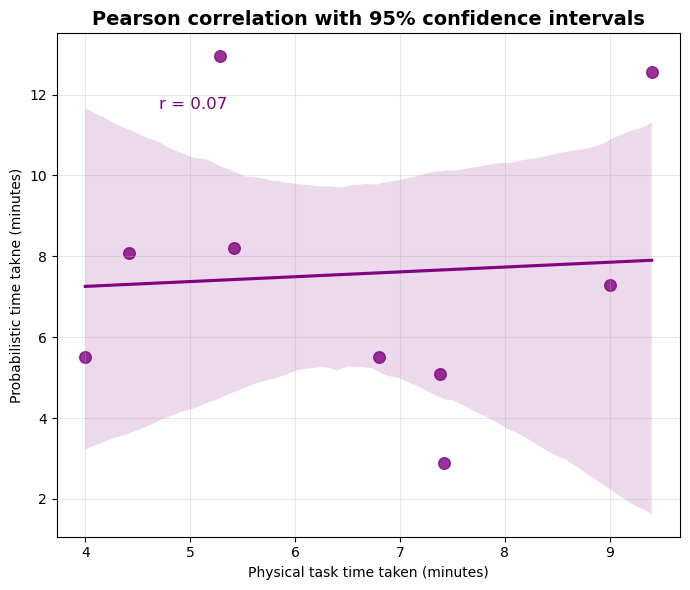

In [ ]:
# -----------------------
# Physical Nomogram Data
# -----------------------
time_taken_phys = [
    7*60 + 25,  # 445s
    5*60 + 25,  # 325s
    9*60 + 0,   # 540s
    9*60 + 24,  # 564s
    6*60 + 48,  # 408s
    4*60 + 0,   # 240s
    4*60 + 25,  # 265s
    7*60 + 23,  # 443s
    5*60 + 17   # 317s
]

# ----------------------------
# Probabilistic Nomogram Data
# ----------------------------
time_taken_proba = [
    2*60 + 53,   # 173s
    8*60 + 13,   # 493s
    7*60 + 17,   # 437s
    12*60 + 34,  # 754s
    5*60 + 30,   # 330s
    5*60 + 30,   # 330s
    8*60 + 5,    # 485s
    5*60 + 6,    # 306s
    12*60 + 57   # 777s
]

# Convert to minutes
time_phys_min = np.array(time_taken_phys) / 60
time_proba_min = np.array(time_taken_proba) / 60

# Correlation (Pearson)
corr, pval = pearsonr(time_phys_min, time_proba_min)
print(f"Correlation (r) = {corr:.3f}, p-value = {pval:.4f}")

# ----------------------------
# Scatter with Regression
# ----------------------------
plt.figure(figsize=(7,6))
sns.regplot(x=time_phys_min, y=time_proba_min, color="purple", marker="o", scatter_kws={'s':70}, ci = 95)

plt.title("Pearson correlation with 95% confidence intervals", fontsize=14, fontweight="bold")
plt.xlabel("Physical task time taken (minutes)")
plt.ylabel("Probabilistic time takne (minutes)")
plt.grid(alpha=0.3)

# Annotate correlation on plot
plt.text(max(time_phys_min)*0.5, max(time_proba_min)*0.9, f"r = {corr:.2f}", fontsize=12, color="purple")

plt.tight_layout()
plt.show()


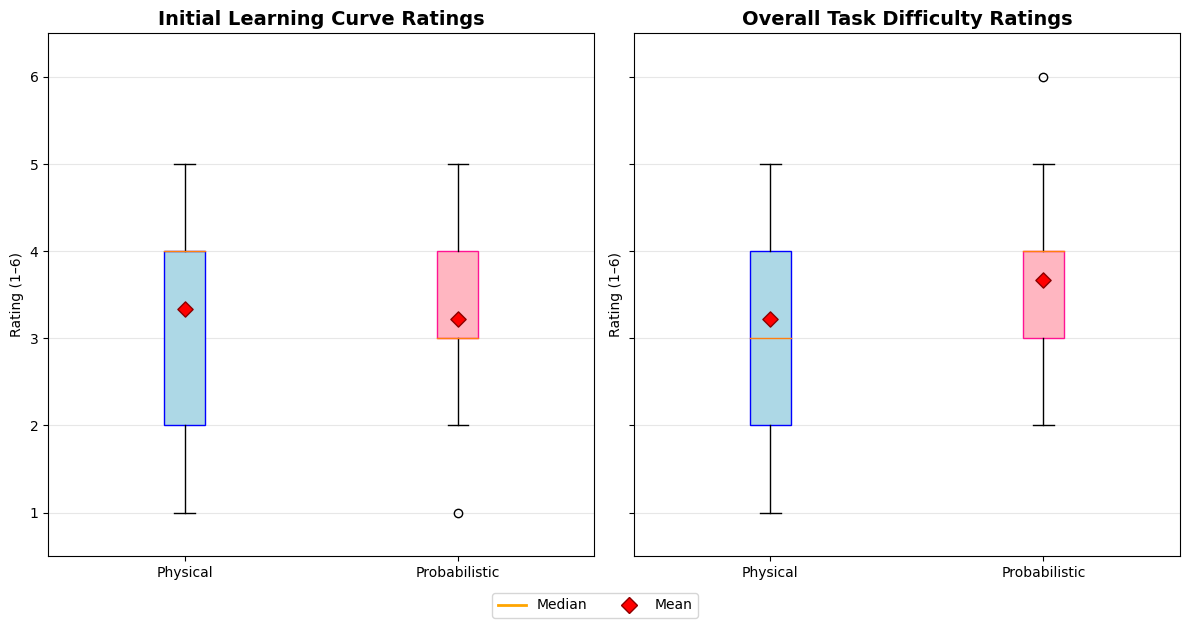

In [ ]:
# -----------------------
# Physical Nomogram Data
# -----------------------
learning_curve_phys = [4, 1, 5, 1, 5, 4, 2, 4, 4]
difficulty_phys = [4, 5, 2, 3, 5, 4, 2, 3, 1]

# ----------------------------
# Probabilistic Nomogram Data
# ----------------------------
learning_curve_proba = [5, 3, 4, 3, 2, 5, 3, 3, 1]
difficulty_proba = [4, 5, 4, 4, 6, 3, 3, 2, 2]

# ----------------------------
# Plot setup
# ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# Boxplot for Learning Curve
bp1 = axes[0].boxplot([learning_curve_phys, learning_curve_proba],
                      labels=["Physical", "Probabilistic"],
                      patch_artist=True,
                      showfliers=True)

# Boxplot for Task Difficulty
bp2 = axes[1].boxplot([difficulty_phys, difficulty_proba],
                      labels=["Physical", "Probabilistic"],
                      patch_artist=True,
                      showfliers=True)

# ----------------------------
# Coloring
# ----------------------------
colors = ["lightblue", "lightpink"]
edges = ["blue", "deeppink"]

for bp, col, edge in zip(bp1['boxes'], colors, edges):
    bp.set_facecolor(col)
    bp.set_edgecolor(edge)

for bp, col, edge in zip(bp2['boxes'], colors, edges):
    bp.set_facecolor(col)
    bp.set_edgecolor(edge)

# ----------------------------
# Add mean markers (red diamonds)
# ----------------------------
def add_means(ax, data):
    for i, values in enumerate(data, start=1):
        mean_val = np.mean(values)
        ax.scatter(i, mean_val, color='red', marker='D', s=60, zorder=3,
                   edgecolors='darkred', linewidth=1)

add_means(axes[0], [learning_curve_phys, learning_curve_proba])
add_means(axes[1], [difficulty_phys, difficulty_proba])

# ----------------------------
# Titles and labels
# ----------------------------
axes[0].set_title("Initial Learning Curve Ratings", fontsize=14, fontweight="bold")
axes[1].set_title("Overall Task Difficulty Ratings", fontsize=14, fontweight="bold")

for ax in axes:
    ax.set_ylabel("Rating (1–6)")
    ax.set_ylim(0.5, 6.5)
    ax.grid(True, alpha=0.3, axis="y")

# ----------------------------
# Legend
# ----------------------------
legend_elements = [
    Line2D([0], [0], color='orange', linewidth=2, label='Median'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='red',
           markeredgecolor='darkred', markersize=8, label='Mean')
]

fig.legend(handles=legend_elements, loc='lower center',
           bbox_to_anchor=(0.5, -0.05), ncol=2)

plt.tight_layout()
plt.show()


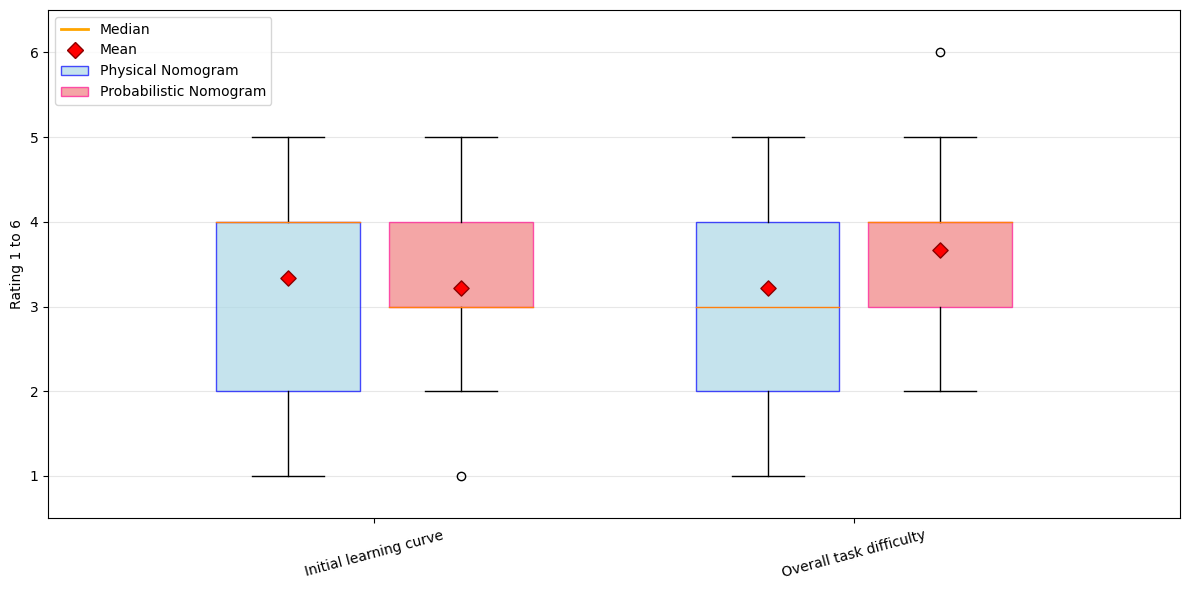

In [97]:
# -----------------------
# Data
# -----------------------
learning_curve_phys = [4, 1, 5, 1, 5, 4, 2, 4, 4]
difficulty_phys      = [4, 5, 2, 3, 5, 4, 2, 3, 1]

learning_curve_proba = [5, 3, 4, 3, 2, 5, 3, 3, 1]
difficulty_proba     = [4, 5, 4, 4, 6, 3, 3, 2, 2]

# Categories
categories = ["Initial learning curve", "Overall task difficulty"]

fig, ax = plt.subplots(figsize=(12, 6))

# Group positions
group_centers = np.arange(1, len(categories) + 1)
offset = 0.18
widths = 0.30

# Build grouped boxplots
data_phys = [learning_curve_phys, difficulty_phys]
data_prob = [learning_curve_proba, difficulty_proba]

pos_phys = group_centers - offset
pos_prob = group_centers + offset

bp_phys = ax.boxplot(
    data_phys,
    positions=pos_phys,
    widths=widths,
    patch_artist=True,
    showfliers=True
)

bp_prob = ax.boxplot(
    data_prob,
    positions=pos_prob,
    widths=widths,
    patch_artist=True,
    showfliers=True
)

# -----------------------
# Colors (Physical = blue, Probabilistic = pink/red)
# -----------------------
for box in bp_phys['boxes']:
    box.set_facecolor('lightblue')
    box.set_edgecolor('blue')
    box.set_alpha(0.7)

for box in bp_prob['boxes']:
    box.set_facecolor('lightcoral')
    box.set_edgecolor('deeppink')
    box.set_alpha(0.7)

# -----------------------
# Add mean markers
# -----------------------
def add_means(ax, datasets, positions):
    for vals, x in zip(datasets, positions):
        m = np.mean(vals)
        ax.scatter(x, m, color='red', marker='D', s=60,
                   edgecolors='darkred', linewidth=1, zorder=3)

add_means(ax, data_phys, pos_phys)
add_means(ax, data_prob, pos_prob)

# -----------------------
# Axes and grid
# -----------------------
ax.set_xticks(group_centers)
ax.set_xticklabels(categories, rotation=15)
ax.set_ylabel("Rating 1 to 6")
ax.set_ylim(0.5, 6.5)
ax.grid(True, axis='y', alpha=0.3)

# -----------------------
# Legend (matching colors)
# -----------------------
legend_elements = [
    Line2D([0], [0], color='orange', linewidth=2, label='Median'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='red',
           markeredgecolor='darkred', markersize=8, label='Mean'),
    Patch(facecolor='lightblue', edgecolor='blue', label='Physical Nomogram', alpha=0.7),
    Patch(facecolor='lightcoral', edgecolor='deeppink', label='Probabilistic Nomogram', alpha=0.7)
]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()
